# 03. 추론통계 — 변수 하나씩 점수와의 관계 검정

**입력**: `dataSet/student_clean.csv` (2,737행)
**출력**: `out/03_*.csv`, `out/03_*.png`, `dataSet/candidate_vars.csv` (회귀 후보 변수 목록)

회귀에 넣을 변수를 고르기 위해 변수 **하나씩** 점수와의 관계를 검정한다.

| 변수 종류 | 검정 | 이유 |
|---|---|---|
| 연속형 23개 | Spearman 상관 | 점수가 정규분포가 아니라서 Pearson 대신 순위 상관 |
| 2집단 명목형 | Mann-Whitney U | 집단별 점수가 정규분포가 아니라서 t검정 대신 비모수 검정 |
| 3집단 이상 명목형 | 일원분산분석 + Tukey 사후검정 | 등분산 확인 후 진행 |

02에서 직선으로 설명이 안 되던 `deep_work_sessions`(0~5 / 6~7회)와 `physical_activity_hours`(0 / 0 초과)는
집단으로 나눠서도 검정한다.

In [1]:
import pandas as pd
import numpy as np
from scipy import stats
import statsmodels.api as sm
from statsmodels.stats.multicomp import pairwise_tukeyhsd
from statsmodels.stats.outliers_influence import variance_inflation_factor
import matplotlib.pyplot as plt
from matplotlib import font_manager

font_manager.fontManager.addfont('NotoSansKR-Regular.ttf')
plt.rcParams['font.family'] = font_manager.FontProperties(fname='NotoSansKR-Regular.ttf').get_name()
plt.rcParams['axes.unicode_minus'] = False
pd.set_option('display.width', 160)

df = pd.read_csv('dataSet/student_clean.csv')
TARGET = 'final_exam_score'
cat_cols = ['gender', 'city_type', 'doomscrolling_before_sleep', 'mental_state', 'learning_style', 'career_goal']
num_cols = [c for c in df.columns if c not in cat_cols + [TARGET]]

## 0. 종속변수 정규성

점수가 정규분포면 Pearson 상관·t검정을 쓸 수 있다. 아니면 순위 기반 검정으로 간다.

In [2]:
w, p = stats.shapiro(df[TARGET])
print(f'Shapiro-Wilk W = {w:.4f}, p = {p:.5f}  →', '정규성 위배' if p < 0.05 else '정규성 만족')

Shapiro-Wilk W = 0.9969, p = 0.00002  → 정규성 위배


점수는 정규분포가 아니다(p < 0.001). 다만 n = 2,737이면 작은 차이도 유의하게 나오므로
왜도 0.06·첨도 −0.24(02)를 보면 정규에서 크게 벗어난 모양은 아니다.
보수적으로 가기 위해 상관은 Spearman, 집단 비교는 비모수 검정을 쓴다.

## 1. 연속형 변수 × 점수 — Spearman 상관

효과크기 해석 기준: |ρ| ≥ 0.3 중간, 0.1~0.3 약함, < 0.1 미미.

In [3]:
def strength(rho):
    r = abs(rho)
    if r >= 0.5: return '강함'
    if r >= 0.3: return '중간'
    if r >= 0.1: return '약함'
    return '미미함'

rows = []
for c in num_cols:
    rho, p = stats.spearmanr(df[c], df[TARGET])
    rows.append({'변수': c, 'rho': round(rho, 3), 'p': p, '방향': '+' if rho > 0 else '-', '강도': strength(rho)})

corr = pd.DataFrame(rows).sort_values('rho', key=abs, ascending=False).reset_index(drop=True)
# 채택 기준: p < 0.05 이면 채택 (|ρ| ≥ 0.1 이거나 유의하면)
corr['채택'] = np.where(corr['p'] < 0.05, '채택', '-')
corr['p'] = corr['p'].apply(lambda v: '<0.001' if v < 0.001 else f'{v:.3f}')
corr.to_csv('out/03_spearman_상관.csv', index=False)
corr

,변수,rho,p,방향,강도,채택
0,consistency_score,0.323,<0.001,+,중간,채택
1,study_hours_per_day,0.306,<0.001,+,중간,채택
2,focus_score,0.285,<0.001,+,약함,채택
3,procrastination_index,-0.277,<0.001,-,약함,채택
4,burnout_risk,-0.252,<0.001,-,약함,채택
5,revision_efficiency,0.216,<0.001,+,약함,채택
6,motivation_level,0.201,<0.001,+,약함,채택
7,social_media_hours,-0.182,<0.001,-,약함,채택
8,stress_level,-0.178,<0.001,-,약함,채택
9,attendance_percentage,0.173,<0.001,+,약함,채택


- 꾸준함(0.32)과 공부시간(0.31)만 중간 수준이고 나머지는 약하거나 미미하다.
  변수 하나로는 점수를 설명하기 어렵다 → 여러 변수를 함께 넣는 다중회귀가 필요한 이유.
- 후보를 놓치지 않으려고 전통적 기준(|ρ| ≥ 0.3) 대신 **p < 0.05 인 변수를 모두 후보로** 올린다. 14개.
- `deep_work_sessions`(0.08)와 `physical_activity_hours`(−0.004)는 아래에서 집단으로 나눠 다시 본다.

## 2. 연속형 독립변수끼리의 상관 — 다중공선성 점검

독립변수끼리 강하게 상관되어 있으면 회귀계수가 불안정해진다. 상위 10쌍과 VIF를 본다.

In [4]:
rho_mat = df[num_cols].corr(method='spearman')
pairs = (rho_mat.where(np.triu(np.ones_like(rho_mat, dtype=bool), k=1))
                .stack().rename('rho').reset_index())
pairs.columns = ['변수1', '변수2', 'rho']
pairs['abs'] = pairs['rho'].abs()
top10 = pairs.sort_values('abs', ascending=False).head(10).drop(columns='abs').round(3)
print('전체', len(pairs), '쌍 중 |ρ| 최대 =', pairs['abs'].max().round(3))
top10.to_csv('out/03_독립변수간_상관_top10.csv', index=False)
top10

전체 529 쌍 중 |ρ| 최대 = 0.067


,변수1,변수2,rho
265,focus_score,procrastination_index,0.067
435,financial_stress,burnout_risk,0.058
342,caffeine_intake,revision_efficiency,0.045
129,social_media_hours,caffeine_intake,-0.045
180,ai_tool_usage_hours,productivity_after_midnight,-0.044
195,gaming_hours,focus_score,-0.043
7,age,ai_tool_usage_hours,-0.041
137,social_media_hours,consistency_score,-0.041
201,gaming_hours,family_support,-0.041
53,deep_work_sessions,ai_tool_usage_hours,0.041


In [5]:
# 범주형 더미까지 함께 넣고 계산한 뒤, 연속형 변수의 VIF만 본다
X = sm.add_constant(pd.get_dummies(df[num_cols + cat_cols], columns=cat_cols, drop_first=True, dtype=float))
vif = pd.Series([variance_inflation_factor(X.values, i) for i in range(1, X.shape[1])], index=X.columns[1:])
print('연속형 변수의 최대 VIF =', vif[num_cols].max().round(2))
vif[num_cols].sort_values(ascending=False).round(3).head()

연속형 변수의 최대 VIF = 1.03


social_media_hours       1.026
gaming_hours             1.017
procrastination_index    1.016
caffeine_intake          1.015
burnout_risk             1.015
dtype: float64

독립변수 간 |ρ| 최대 0.07, VIF 최대 1.03. 사실상 서로 무상관이다.
실제 교육 데이터라면 집중도·동기·스트레스·번아웃은 서로 얽혀 있는 게 보통인데, 여기선 전부 독립이다.
변수를 하나씩 독립적으로 생성한 합성 데이터라는 뜻이고, 그래서 단변량 결과와 다중회귀 결과가 거의 같게 나온다 (04에서 확인).

## 3. 2집단 비교 — Mann-Whitney U

대상: `doomscrolling_before_sleep`(0/1), `gender`, 그리고 집단으로 나눈 `physical_activity_hours`(0 / 0 초과).
먼저 집단별 정규성을 확인하고, 위배되면 Mann-Whitney U를 쓴다.

In [6]:
df['pa_group'] = np.where(df['physical_activity_hours'] > 0, '활동 O', '활동 X')
df['dw_group'] = np.where(df['deep_work_sessions'] >= 6, '6~7회', '0~5회')

def two_group_test(col):
    g = df.groupby(col)[TARGET]
    names = list(g.groups)
    a, b = g.get_group(names[0]), g.get_group(names[1])
    # 집단별 정규성 (Shapiro-Wilk)
    normal = all(stats.shapiro(x).pvalue >= 0.05 for x in (a, b))
    u, p = stats.mannwhitneyu(a, b, alternative='two-sided')
    return {'변수': col, '집단': f'{names[0]} vs {names[1]}', 'n': f'{len(a)} / {len(b)}',
            '평균': f'{a.mean():.2f} / {b.mean():.2f}', '정규성': '만족' if normal else '위배',
            'U': u, 'p': p, '유의': p < 0.05}

mw = pd.DataFrame([two_group_test(c) for c in ['doomscrolling_before_sleep', 'gender', 'pa_group', 'dw_group']])
mw.to_csv('out/03_mannwhitney.csv', index=False)
mw

,변수,집단,n,평균,정규성,U,p,유의
0,doomscrolling_before_sleep,0 vs 1,1380 / 1357,57.34 / 52.13,위배,1080968.5,2.592743e-12,True
1,gender,Female vs Male,1388 / 1349,55.10 / 54.41,위배,955266.5,3.563906e-01,False
2,pa_group,활동 O vs 활동 X,2424 / 313,55.10 / 52.13,위배,415443.5,6.085748e-03,True
3,dw_group,0~5회 vs 6~7회,2054 / 683,53.18 / 59.51,위배,570604.5,2.594659e-13,True


- 취침 전 스마트폰: 안 하는 집단 점수가 유의하게 높다 (p < 0.001).
- 신체활동: 0시간 집단이 유의하게 낮다 (p = 0.006). 연속형으로는 비유의(p = 0.82)였는데 집단으로 나누니 차이가 보인다.
- 집중학습 6~7회 집단이 유의하게 높다 (p < 0.001).
- 성별은 차이 없음.

## 4. 3집단 이상 비교 — 일원분산분석 + Tukey 사후검정

대상: `mental_state`, `city_type`, `learning_style`, `career_goal`, 그리고 0~7회 그대로의 `deep_work_sessions`.
등분산성(Levene)을 먼저 확인하고, 위배되면 Welch 분산분석으로 바꾼다. 효과크기는 η²(집단 간 제곱합 / 전체 제곱합).

In [7]:
from statsmodels.stats.oneway import anova_oneway

def anova_test(col):
    groups = [g[TARGET].values for _, g in df.groupby(col)]
    lev_p = stats.levene(*groups).pvalue
    if lev_p >= 0.05:
        f, p = stats.f_oneway(*groups)
        method = '일원분산분석'
    else:
        res = anova_oneway(df[TARGET], df[col], use_var='unequal')
        f, p, method = res.statistic, res.pvalue, 'Welch'
    grand = df[TARGET].mean()
    ss_between = sum(len(g) * (g.mean() - grand) ** 2 for g in groups)
    ss_total = ((df[TARGET] - grand) ** 2).sum()
    return {'변수': col, '집단 수': len(groups), '등분산(Levene p)': round(lev_p, 3), '검정': method,
            'F': round(f, 2), 'p': p, 'eta2': round(ss_between / ss_total, 3), '유의': p < 0.05}

anova = pd.DataFrame([anova_test(c) for c in ['mental_state', 'city_type', 'learning_style', 'career_goal', 'deep_work_sessions']])
anova.to_csv('out/03_anova.csv', index=False)
anova

,변수,집단 수,등분산(Levene p),검정,F,p,eta2,유의
0,mental_state,4,0.954,일원분산분석,97.25,8.272781e-60,0.096,True
1,city_type,3,0.032,Welch,2.89,5.573128e-02,0.002,False
2,learning_style,4,0.252,일원분산분석,0.60,6.144882e-01,0.001,False
3,career_goal,5,0.288,일원분산분석,0.60,6.608396e-01,0.001,False
4,deep_work_sessions,8,0.864,일원분산분석,9.73,5.126674e-12,0.024,True


`city_type`만 등분산이 깨져(Levene p = 0.03) Welch 검정으로 바꿨고, 결과는 그래도 비유의(p = 0.056).
`mental_state`(η² = 0.096, 중간)와 `deep_work_sessions`만 유의하다. 도시·학습 스타일·진로는 차이 없음.

유의한 두 변수는 **어느 집단끼리** 다른지 Tukey HSD로 본다.

In [8]:
for col in ['mental_state', 'deep_work_sessions']:
    tk = pairwise_tukeyhsd(df[TARGET], df[col].astype(str), alpha=0.05)
    res = pd.DataFrame(tk.summary().data[1:], columns=tk.summary().data[0])
    res.to_csv(f'out/03_tukey_{col}.csv', index=False)
    print(f'\n[{col}] 집단별 평균')
    print(df.groupby(col)[TARGET].mean().round(2))
    print(f'\n[{col}] Tukey HSD — 유의한 쌍만')
    print(res[res['reject'] == True][['group1', 'group2', 'meandiff', 'p-adj']].to_string(index=False))


[mental_state] 집단별 평균
mental_state
Balanced      54.63
Burnout       46.90
Distracted    54.49
Focused       63.31
Name: final_exam_score, dtype: float64

[mental_state] Tukey HSD — 유의한 쌍만
    group1     group2  meandiff  p-adj
  Balanced    Burnout   -7.7375    0.0
  Balanced    Focused    8.6810    0.0
   Burnout Distracted    7.5903    0.0
   Burnout    Focused   16.4186    0.0
Distracted    Focused    8.8283    0.0



[deep_work_sessions] 집단별 평균
deep_work_sessions
0    54.92
1    53.35
2    52.95
3    53.53
4    52.69
5    51.72
6    58.42
7    60.51
Name: final_exam_score, dtype: float64

[deep_work_sessions] Tukey HSD — 유의한 쌍만
group1 group2  meandiff  p-adj
     0      7    5.5928 0.0019
     1      6    5.0696 0.0077
     1      7    7.1650 0.0000
     2      6    5.4638 0.0036
     2      7    7.5591 0.0000
     3      6    4.8852 0.0165
     3      7    6.9806 0.0000
     4      6    5.7263 0.0012
     4      7    7.8217 0.0000
     5      6    6.6940 0.0001
     5      7    8.7893 0.0000


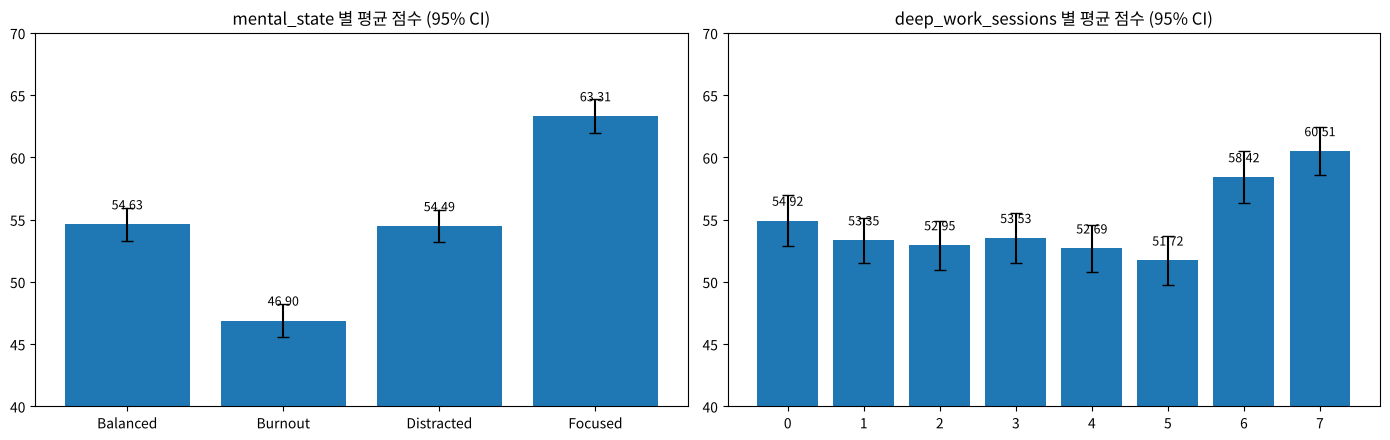

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, col in zip(axes, ['mental_state', 'deep_work_sessions']):
    g = df.groupby(col)[TARGET].agg(['mean', 'sem'])
    ax.bar(g.index.astype(str), g['mean'], yerr=g['sem'] * 1.96, capsize=4)
    ax.set_ylim(40, 70)
    ax.set_title(f'{col} 별 평균 점수 (95% CI)')
    for i, m in enumerate(g['mean']):
        ax.text(i, m + 1.2, f'{m:.2f}', ha='center', fontsize=9)
fig.tight_layout()
fig.savefig('out/03_사후검정_평균.png', dpi=120)
plt.show()

- `mental_state`: Focused(63.3) > Balanced(54.6) ≈ Distracted(54.5) > Burnout(46.9).
  Balanced와 Distracted는 차이가 없다(p = 0.999) → 회귀에서는 두 집단을 기준집단으로 합친다.
- `deep_work_sessions`: 7회는 0~5회 전부보다, 6회는 1~5회보다 유의하게 높다(0 vs 6만 p = 0.23).
  6회와 7회 사이, 0~5회 서로 간에는 차이가 없다.
  → "0~5회 / 6~7회" 두 집단 더미로 넣는 것이 횟수 그대로 넣는 것보다 맞는 표현이다.

## 5. 회귀 후보 변수 확정

유의했던 변수를 모아 04로 넘긴다.

In [10]:
sig_num = corr.loc[corr['채택'] == '채택', '변수'].tolist()
sig_num = [c for c in sig_num if c not in ('deep_work_sessions',)]   # deep_work는 그룹 더미로 대체

candidates = pd.DataFrame({
    '변수': sig_num + ['doomscrolling_before_sleep', 'mental_state', 'deep_work_sessions', 'physical_activity_hours'],
    '표현': ['연속형'] * len(sig_num) + ['더미(No 기준)', '더미(Balanced+Distracted 기준)',
                                        '더미(0~5회 기준, 6~7회)', '후보: 더미(0시간 기준) — 04에서 비교'],
})
candidates.to_csv('dataSet/candidate_vars.csv', index=False)
print(len(candidates), '개')
candidates

17 개


,변수,표현
0,consistency_score,연속형
1,study_hours_per_day,연속형
2,focus_score,연속형
3,procrastination_index,연속형
4,burnout_risk,연속형
5,revision_efficiency,연속형
6,motivation_level,연속형
7,social_media_hours,연속형
8,stress_level,연속형
9,attendance_percentage,연속형
